# Lab 02: How a model asks for a tool

**Notebook 2 of 2: tool calling at the Chinook desk**

## Goal

Take the tool-call round trip to a real job: the support desk of a music shop, where a rep asks about a customer
and the answer is in the shop's database. We write a database lookup as a plain Python function, describe it to the
model, and carry one question through by hand: the model asks for the lookup, our code runs it, and the model
answers from the row that came back. Then we send back a result that does not match the database and read what the
model does with it. By the end you can connect a model to a lookup of your own, and you know which part of the
round trip has to be right for the answer to be right.

## What you will learn

- How to open the shop's database read-only and write a lookup as a plain Python function.
- How to describe that lookup as a tool, with its argument, so the model can ask for it.
- How to run one round trip: read the tool call, run the lookup, send the row back with the call's id.
- Why the answer depends on the tool result: the model repeats what our code sends back.
- Why a question that needs several lookups needs more than one round trip.

## From the playground to the desk

In notebook 1 we asked a model to roll two dice. Three things carry over:

- A **tool schema** describes one of our functions to the model: its name, its description and its arguments.
- A **tool call** is the model's request. The reply has `finish_reason` `tool_calls` and no text; it holds an `id`,
  the function's name and the `arguments` as a JSON string. The model runs nothing.
- A **`tool` message** is our answer: the function's result as a string, with the same id.

Now we take it seriously. The function reads a shop's records, and a rep will repeat the answer to a customer.
This notebook restates everything it uses, so it runs on its own.

## Setup

The first cell finds the repository folder, reads the model name from `models.env`, and takes the key from
`.env` without printing it.

In [1]:
from pathlib import Path
import json
import os
import sqlite3
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


We call the model through **Chat Completions** (`client.chat.completions.create`): a list of messages goes in, one
message comes back. It is the plainest place to watch a tool call, because every step is a message we can print.
OpenAI's newer Responses API, and the frameworks built on these APIs, do the same round trip under other field names
(Going further has the mapping).

Every call passes `reasoning_effort=EFFORT or omit`: the effort setting from `models.env`, or no setting at all
when that line is empty (`omit` is the `openai` package's way to leave an argument out of a request).

In [2]:
from openai import OpenAI, omit

client = OpenAI(timeout=60)

---

## Part A: Meet the shop, read one customer's row, and ask the model about her

Chinook is a small music shop that sells tracks online. Its support desk answers the reps' questions about
customers and their invoices, and everything the desk can look up is in one SQLite file, `data/chinook.db`.

We open the file **read-only**, so nothing we write in this notebook can change the shop's data:

- `file:...?mode=ro` is the file's address with the read-only mode added, and `uri=True` tells `sqlite3` to read it
  as an address and not as a plain file name.
- `check_same_thread=False` allows the connection to be used from another thread. Nothing in this notebook needs
  it, and you can ignore it.

The cell then runs two queries in SQL, the language of the database:

- `SELECT COUNT(*) FROM customers` asks the database how many rows the `customers` table has.
- `SELECT ... FROM customers WHERE LastName = 'Holý'` returns the columns we name, for the rows whose last name is
  Holý.

`.fetchone()` returns one row as a tuple, and `[0]` takes the first value in it.

Before any function or any model, we look at the data itself: how many customers there are, and one customer's row.

In [3]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)

print("customers:", conn.execute("SELECT COUNT(*) FROM customers").fetchone()[0])

row = conn.execute(
    "SELECT CustomerId, FirstName, LastName, Country FROM customers WHERE LastName = 'Holý'"
).fetchone()
print(row)

customers: 59
(6, 'Helena', 'Holý', 'Czech Republic')


The `customers` table has 59 rows. The one we asked for comes back as a tuple, in the order of the columns we
named:

| Column | Value | What it is |
|---|---|---|
| `CustomerId` | `6` | the number every other table uses for this customer |
| `FirstName`, `LastName` | `Helena`, `Holý` | stored in two columns |
| `Country` | `Czech Republic` | where she lives |

Helena Holý is the customer we follow in this notebook. Now a rep asks the desk about her:

> Is Helena Holý one of our customers? Which country is she in?

We have just read the answer ourselves. Can the model? We send the question with a short system message that says
whose assistant it is, and no tools.

In [4]:
SYSTEM = "You help the support reps of a music shop. Answer in one or two sentences."
QUESTION = "Is Helena Holý one of our customers? Which country is she in?"

messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)

I can’t determine that from the information provided. Please share the customer records or a lookup result, and I can confirm whether Helena Holý is a customer and which country she’s in.


In our run the model said that it could not determine this from the information provided, and asked us for the customer records or a lookup result.

That answer fits what the model received: two messages and nothing else. `chinook.db` is a file on our
machine, and no part of it was in the request.

**If your run names a country anyway,** nothing was looked up either. Chinook is a public sample database, and a copy of
it may be in the model's training data. An answer written from training data can be right, and it would stay the
same if we changed Helena's row tomorrow. The desk needs answers read from the file.

**Checkpoint A.** 59 customers; the row `(6, 'Helena', 'Holý', 'Czech Republic')`; without a tool the model says it
cannot tell from what it was given.

---

## Part B: Write the lookup as a plain function, then describe it as a tool

The model needs a way to ask for Helena's row. We give it one in two steps: first a Python function that does the
lookup, tested by hand, and then a description of that function for the model.

### The lookup, called by hand

`find_customer(name)` finds a customer by full name. Read the query inside it:

- `FirstName || ' ' || LastName` joins the two name columns with a space (`||` is how SQL joins text), so we can
  compare against a full name such as `Helena Holý`.
- `= ?` is a placeholder. `sqlite3` fills it from the tuple `(name,)`, and it treats the value as data, never as
  SQL. A name typed by a person, or written by a model, cannot change the query.
- `.fetchall()` returns every matching row as a list, and the last line turns each row into a dictionary with
  readable keys.

The function returns a **list**, because a name can match one customer, several or none.

In [5]:
def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


print(find_customer("Helena Holý"))

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


One match, with the same three facts as the row we read in Part A: `customer_id` 6, the full name, the country. The
function works, and no model was involved.

### The same function, described for the model

**Important:** the model never sees this Python, and it never touches the database. What we send with a request
is a **tool schema**: a dictionary that describes the function. Here it is beside the function it describes:

| In the function | In the schema | What the model does with it |
|---|---|---|
| `def find_customer` | `"name": "find_customer"` | writes this name to ask for the lookup |
| the docstring's first line | `"description"` | reads it to decide *when* to ask for the lookup |
| the argument `name: str` | `"properties": {"name": {"type": "string", ...}}` | reads it to know which value to send, and of what type |
| the docstring's `Args:` line | the property's `"description"` | reads it to know what to put in `name` |

The schema has two layers. The outer dictionary says what kind of tool this is (`"type": "function"`). The inner
`function` dictionary holds the name, the description and `parameters`.

`parameters` is written in JSON Schema, a standard way to describe JSON data:

- `"type": "object"`: the arguments arrive as one JSON object, a set of names and values.
- `"properties"`: the names it may hold. One here, `name`, a string.
- `"required": ["name"]`: the model must always send it.
- `"additionalProperties": False` and `"strict": True`: the arguments must match this schema exactly, with no
  other names.

In [6]:
find_customer_tool = {
    "type": "function",
    "function": {
        "name": "find_customer",
        "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
        "parameters": {
            "type": "object",
            "properties": {
                "name": {"type": "string", "description": "First and last name, for example 'Ana Silva'."}
            },
            "required": ["name"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

The SQL is not in the schema, and neither is the file. The model will receive this much: a lookup called
`find_customer` exists and takes a name. What the lookup does when it runs stays on our side.

**Checkpoint B.** `find_customer("Helena Holý")` returns a list with one dictionary:
`{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}`.

---

## Part C: Run one round trip at the desk

The same question as in Part A, and this time the request carries `tools=[find_customer_tool]`. A round trip has
three moves: the model asks, our code runs the lookup, our code sends the result back.

### The model asks

`messages` still holds the system message and the rep's question. We print why the model stopped, the text of its
reply, and the first tool call as JSON.

In [7]:
response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=[find_customer_tool],
    reasoning_effort=EFFORT or omit,
)

reply = response.choices[0].message
call = reply.tool_calls[0]

print("finish_reason:", response.choices[0].finish_reason)
print("content:      ", reply.content)
print(call.model_dump_json(indent=2))

finish_reason: tool_calls
content:       None
{
  "id": "call_qZPbbU7ysGx3NEkECTonV6kC",
  "function": {
    "arguments": "{\"name\":\"Helena Holý\"}",
    "name": "find_customer"
  },
  "type": "function"
}


The model did not answer. It asked:

- `finish_reason` is `tool_calls`: the model stopped because it is asking for a tool. (A finished answer has `stop`.)
- `content` is `None`: there is no text.
- The call has an `id` that labels this request (`call_qZPbbU7ysGx3NEkECTonV6kC` in our run; yours differs), the `name` of the function
  it asks for, and `arguments`.

Look at `arguments`. Printed on its own it reads `{"name":"Helena Holý"}`. It is a **string** of JSON, and the model wrote it.
(The backslashes in the output above are how JSON writes a quote mark inside a string.) The rep's question said
"Helena Holý", and the model placed that name under the key `name`, as the schema asked.

Nothing has touched the database since Part B. A tool call is a few lines of data, and what happens next is up to
our code.

### Our code runs the lookup

`json.loads` turns the `arguments` string into a Python dictionary, and `find_customer(**args)` passes its items as
the function's arguments: `{"name": "Helena Holý"}` becomes `name="Helena Holý"`.

In [8]:
args = json.loads(call.function.arguments)
print("args:  ", args)

result = find_customer(**args)
print("result:", result)

args:   {'name': 'Helena Holý'}
result: [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


This cell sent nothing to the model. It ran our function on our machine, with the name the model wrote, and the
database returned Helena's row.

### Our code sends the result back

The model is waiting for the answer to its request. We add two messages to the list and send the whole list again:

1. `reply`, the model's own message with the tool call in it. The API needs to see the request before its answer.
   We append the object as it came back; the client accepts it next to our dictionaries.
2. A message with the role `tool`. Its `tool_call_id` is the `id` of the call it answers, and its `content` is the
   result as a string. `json.dumps` turns our list into that string, and `ensure_ascii=False` keeps the `ý` in
   Holý readable.

The list then holds four messages:

| # | Role | What it holds | Who wrote it |
|---|---|---|---|
| 1 | `system` | whose assistant this is | we did |
| 2 | `user` | the rep's question | the rep |
| 3 | `assistant` | the tool call for `find_customer` | the model |
| 4 | `tool` | Helena's row, with the call's id | our code |

In [9]:
messages.append(reply)
messages.append({"role": "tool", "tool_call_id": call.id, "content": json.dumps(result, ensure_ascii=False)})

response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=[find_customer_tool],
    reasoning_effort=EFFORT or omit,
)

print("finish_reason:", response.choices[0].finish_reason)
print(response.choices[0].message.content)

finish_reason: stop
Yes, Helena Holý is one of our customers, and she’s in the Czech Republic.


`finish_reason` is `stop`, and the reply is an answer: Helena Holý is one of our customers, and she is in the Czech Republic. The country in it is the `country` of the row our
function returned. This answer was read from the file.

The picture shows the round trip we just ran, in five steps. The lime note marks the point where our code decides.

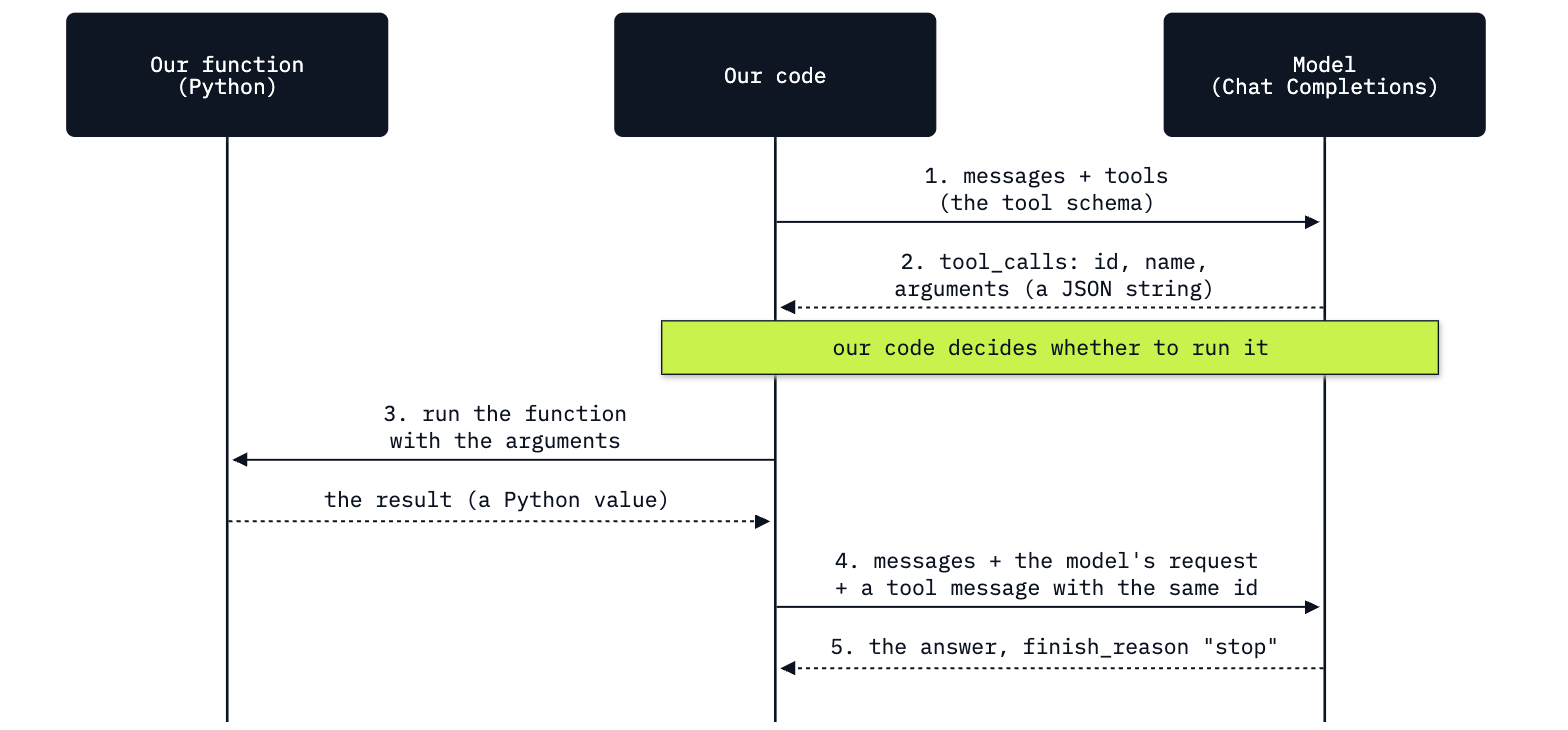

In [10]:
from IPython.display import Image

Image("resources/lab02_tool_call_round_trip.png", width=760)

Read it with the desk's values:

1. Our code sent the messages and the schema of `find_customer`.
2. The model answered with a tool call: an id, the name `find_customer`, the arguments `{"name":"Helena Holý"}`.
3. Our code ran `find_customer(name="Helena Holý")` against `chinook.db`.
4. Our code sent the list again, with the model's request and a `tool` message that carries the same id and the
   row.
5. The model wrote the answer from the row.

**Notice** which steps touch the shop's data: only step 3, and it is our Python. The model wrote a request and an
answer. This is where a desk puts its rules: which lookups exist, what they may read, and whether a call is run at
all.

**Checkpoint C.** The tool call names `find_customer` with `{"name":"Helena Holý"}`; `result` holds customer 6; the final
reply has `finish_reason` `stop` and says the Czech Republic.

---

## Part D: What the model does with a wrong tool result

The answer in Part C was right because the row was right. The model had nothing else to answer from. So what happens to
the answer when the result we send back is wrong?

To find out we need a number we can check. A second lookup counts a customer's invoices.

### A second lookup, and what the database says

`get_invoices(customer_id)` takes the customer's number, counts the rows in the `invoices` table that carry it, and
adds up their `Total` column. `COUNT(*)` counts rows; `ROUND(SUM(Total), 2)` adds the totals and rounds to cents.

In [11]:
def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


print(get_invoices(6))

{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}


Customer 6 has **7 invoices**, and they add up to **\$49.62**. That is what the database says, and it is the answer
we will check the model against.

The schema follows the same pattern as before. The one argument is a whole number this time, so its type is
`integer`.

In [12]:
get_invoices_tool = {
    "type": "function",
    "function": {
        "name": "get_invoices",
        "description": "Count a customer's invoices and add up their total in US dollars.",
        "parameters": {
            "type": "object",
            "properties": {
                "customer_id": {"type": "integer", "description": "The customer's customer_id."}
            },
            "required": ["customer_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

### A round trip with the true result

A new question, so a new list of messages. We offer both tools, and the model picks one by its name and
description. The cell does the whole round trip, with the same lines as Part C.

We call `get_invoices` ourselves because we know which tool this question needs; the first printed line shows
that the model chose it. Code that has to serve any question reads `call.function.name` and runs the function
with that name.

In [13]:
INVOICES = "How many invoices does customer 6 have, and what do they add up to?"
TOOLS = [find_customer_tool, get_invoices_tool]

messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": INVOICES},
]

# The model asks
response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit)
reply = response.choices[0].message
call = reply.tool_calls[0]
print("the model asks for:", call.function.name, call.function.arguments)

# Our code runs the lookup
result = get_invoices(**json.loads(call.function.arguments))
print("the lookup returns:", result)

# Our code sends the result back
messages.append(reply)
messages.append({"role": "tool", "tool_call_id": call.id, "content": json.dumps(result)})
response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit)
print("the model answers: ", response.choices[0].message.content)

the model asks for: get_invoices {"customer_id":6}
the lookup returns: {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}


the model answers:  Customer 6 has 7 invoices, totaling $49.62.


The model asked for `get_invoices` with `{"customer_id":6}`, the lookup returned 7 invoices and 49.62, and the reply says
the same: "Customer 6 has 7 invoices, totaling \$49.62."

### The same round trip with a wrong result

Now we change one thing. The last message in the list is our `tool` message. We replace its `content` with a
result that says **2** invoices where the database has 7, and ask again. The question, the model's request and the
id stay as they were.

Think of a lookup with a bug, a report that counts only this year, or a row that is out of date. In the `tool` message, all of them look like this.

Before you run it: what will the model say?

In [14]:
wrong_result = {"customer_id": 6, "invoice_count": 2, "total": 49.62}
messages[-1]["content"] = json.dumps(wrong_result)

response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit)

print("finish_reason:    ", response.choices[0].finish_reason)
print("the model answers:", response.choices[0].message.content)

finish_reason:     stop
the model answers: Customer 6 has 2 invoices, totaling $49.62.


In our run: "Customer 6 has 2 invoices, totaling \$49.62."

Put the three numbers side by side:

| Where | Invoices for customer 6 |
|---|---|
| the database (`get_invoices(6)`) | 7 |
| the `tool` message we sent | 2 |
| the model's answer | 2 |

There is no error and no warning, and `finish_reason` is `stop`: a normal, finished answer. The model did not
call the lookup again to check, and it could not have checked in any other way. The `tool` message is the only
thing it has about this customer's invoices.

**Key lesson:** the model answers from what our code sends back. A tool call gives the model a way to *ask*; whether
the answer is true depends on the function that runs and the result our code sends back. This is the part of the
round trip to protect: test the lookups against the database, and log what each tool returned next to the answer
that used it.

**Checkpoint D.** `get_invoices(6)` gives 7 invoices and 49.62, and the first reply says 7. After the `tool` message
is changed, the reply says 2 invoices, with `finish_reason` `stop`.

---

## A question with several lookups needs a loop

Each question so far needed one lookup. A rep is more likely to ask:

> How many invoices does Helena Holý have?

That needs `find_customer` first, to get her `customer_id`, and then `get_invoices` with the id that came back.
The second request depends on the first result, so after one round trip the model's reply would be another tool
call and not an answer. We cannot know in advance how many round trips a question takes. Code that repeats the
round trip until a reply has no tool call in it is called the **agent loop**. We do not run it here: this lab
stops at one round trip, and the agent loop is the subject of the next lab.

---

## What you can do now

- Open a SQLite database read-only and write a lookup as a plain function that returns a list or a dictionary
  (Parts A and B).
- Describe the lookup as a tool schema, with its argument's type and description (Part B).
- Run one round trip by hand: read the tool call, run the lookup, send the result back with the call's id (Part C).
- Explain why a wrong tool result becomes a wrong answer with no error, and name what to protect (Part D).
- Say why a question that needs two lookups needs more than one round trip (the section after Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `sqlite3.OperationalError: unable to open database file` | `data/chinook.db` is missing from the repository folder | restore the file (clone the repository again, or `git checkout data/chinook.db`) |
| `400 - Function tools with reasoning_effort are not supported for ... in /v1/chat/completions. To use function tools, use /v1/responses or set reasoning_effort to 'none'.` | on Chat Completions, the model in `models.env` calls function tools only with the effort `none` | set `REASONING_EFFORT=none` in `models.env` (or leave it empty for a model that has no reasoning setting) |
| `TypeError: 'NoneType' object is not subscriptable` on `reply.tool_calls[0]` | the model answered in text and asked for no tool, so `tool_calls` is `None` | print `reply.content`; check `finish_reason` before reading `tool_calls` |
| a 400 that mentions `tool_call_id` or "must be followed by tool messages" | the `tool` message is missing, or its id is not the call's id | see "The two errors of a broken round trip" in Going further |

## Challenge

1. **A third lookup.** The desk also needs to name the support rep who looks after a customer. Here is the
   function:

   ```python
   def get_support_rep(customer_id: int) -> dict:
       """Name the support rep who looks after a customer."""
       row = conn.execute(
           "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
           "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
       return {"customer_id": customer_id, "support_rep": row[0] if row else None}
   ```

   Call it by hand for customer 6, write its tool schema, offer all three tools and ask: *Who is the support rep
   of customer 6?* Do the whole round trip. Expected: the model asks for `get_support_rep` with
   `{"customer_id":6}`, and the reply names Steve Johnson, the name your hand call returned.
2. **An empty result.** Ask Part C's question again (*Is Helena Holý one of our customers? Which country is she
   in?*) and, when the model asks for `find_customer`, do not run it: send back `"[]"`, an empty list, as the
   `tool` message. Expected: the model says it found no customer by that name, although she is customer 6. The model repeats a
   result that says "nothing" like any other.

The worked solution, run with its outputs, is in `solved/02b_tool_calling_at_the_desk_solution.ipynb`.

## Going further

### The two errors of a broken round trip

The API checks one rule about the message list: every tool call in an `assistant` message must be answered by a
`tool` message with the same id, before anything else is sent. Break the rule and the request is refused with a
400. We trigger both cases on purpose and print the messages.

First a `tool` message with an id that no call has:

In [15]:
from openai import BadRequestError

messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]
response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit)
reply = response.choices[0].message

try:
    client.chat.completions.create(
        model=MODEL,
        messages=messages + [reply, {"role": "tool", "tool_call_id": "call_wrong123", "content": "[]"}],
        tools=TOOLS,
        reasoning_effort=EFFORT or omit,
    )
except BadRequestError as error:
    print(error.message)

Error code: 400 - Invalid parameter: 'tool_call_id' of 'call_wrong123' not found in 'tool_calls' of previous message.


Then no `tool` message at all: the model's request is followed straight away by a new `user` message.

In [16]:
try:
    client.chat.completions.create(
        model=MODEL,
        messages=messages + [reply, {"role": "user", "content": "Well?"}],
        tools=TOOLS,
        reasoning_effort=EFFORT or omit,
    )
except BadRequestError as error:
    print(error.message)

Error code: 400 - An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'. The following tool_call_ids did not have response messages: call_4lQ9GOQoSrFziHJoGqa9U7zw


Both messages state the rule. The first says the id we sent is not among the `tool_calls` of the message before it;
the second says an assistant message with tool calls must be followed by a tool message for each id, and lists the
id that got none. When a reply holds two calls, that means two `tool` messages.

### Run the wrong result several times

One run shows what happened once. To see whether the model *ever* questions the wrong count, repeat the request
and read the replies. The cell rebuilds Part D's list with the wrong result and sends it five times.

In [17]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": INVOICES},
]
response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit)
reply = response.choices[0].message
messages.append(reply)
messages.append({"role": "tool", "tool_call_id": reply.tool_calls[0].id, "content": json.dumps(wrong_result)})

for run in range(1, 6):
    response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, reasoning_effort=EFFORT or omit)
    print(run, response.choices[0].message.content)

1 Customer 6 has 2 invoices totaling $49.62.


2 Customer 6 has 2 invoices totaling $49.62.


3 Customer 6 has 2 invoices, totaling $49.62.


4 Customer 6 has 2 invoices totaling $49.62.


5 Customer 6 has 2 invoices totaling $49.62.


Five replies in our run, and every one says 2 invoices. None of them mentions a doubt.

### The same round trip on the Responses API

Chat Completions is where tool calling started, and it is the form most other providers copy. OpenAI's newer
Responses API runs the same round trip with other names:

| Step | Chat Completions (this lab) | Responses API |
|---|---|---|
| the model's request | `message.tool_calls[i]` with `id`, `function.name`, `function.arguments` | an output item of type `function_call` with `call_id`, `name`, `arguments` |
| our answer | a message with role `tool` and `tool_call_id` | an input item of type `function_call_output` with `call_id` |
| the schema | `{"type": "function", "function": {...}}` | the same fields one level up: `{"type": "function", "name": ..., "parameters": ...}` |

The idea does not change: the model writes a name and a JSON string, and our code decides what runs.

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, the round trip on Chat Completions and on Responses
- [OpenAI API reference: create chat completion](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `tools`, `tool_calls` and the fields of a `tool` message
- [Understanding JSON Schema: object](https://json-schema.org/understanding-json-schema/reference/object):
  `properties`, `required`, `additionalProperties`
- [Python: `sqlite3`](https://docs.python.org/3/library/sqlite3.html): placeholders and read-only connections
  (`mode=ro` with `uri=True`)
- [Python: `json`](https://docs.python.org/3/library/json.html): `json.loads`, `json.dumps` and `ensure_ascii`

Back to [notebook 1](02a_meet_tool_calling.ipynb). Next:
[Lab 03: How to write the agent loop](../03_Agent_Loop/README.md).